In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv(r"D:\Sasi\GUVI HCL AI-ML\Credit_Segmentation_Project\dataset\cleaned\cleaned_loans_granting_model_dataset.csv")
display(df.head())
display(df.shape)

,id,issue_d,revenue,dti_n,loan_amnt,fico_n,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,emp_length_n
0,68407277,2015-12-01,55000.0,5.91,3600,677.0,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,10.0
1,68355089,2015-12-01,65000.0,16.06,24700,717.0,10+ years,small_business,MORTGAGE,SD,577xx,0,10.0
2,68341763,2015-12-01,71000.0,13.85,20000,697.0,10+ years,home_improvement,MORTGAGE,IL,605xx,0,10.0
3,68476807,2015-12-01,104433.0,25.37,10400,697.0,3 years,major_purchase,MORTGAGE,PA,174xx,0,3.0
4,68426831,2015-12-01,34000.0,10.20,11950,692.0,4 years,debt_consolidation,RENT,GA,300xx,0,4.0


(1347147, 13)

In [4]:
# Calculate default counts and percentages
default_counts = df['Default'].value_counts(normalize=True) * 100
print("Overall Default Distribution (%):")
print(default_counts)

Overall Default Distribution (%):
Default
0    80.024006
1    19.975994
Name: proportion, dtype: float64


In [5]:
# Default rate by loan purpose
purpose_default = df.groupby('purpose')['Default'].agg(['count', 'mean']).rename(
    columns={'count': 'Total_Loans', 'mean': 'Default_Rate'}
).sort_values(by='Default_Rate', ascending=False)

print("Default Rate by Loan Purpose:")
purpose_default

Default Rate by Loan Purpose:


,Total_Loans,Default_Rate
purpose,,
small_business,15570,0.298523
renewable_energy,936,0.237179
moving,9513,0.234101
house,7291,0.219174
medical,15601,0.218319
debt_consolidation,780882,0.211501
other,78226,0.210812
educational,423,0.208038
vacation,9080,0.191740


In [12]:
home_default = df.groupby('home_ownership_n')['Default'].agg(['count', 'mean']).rename(
    columns={'count': 'Total_Loans', 'mean': 'Default_Rate'}
).sort_values(by='Default_Rate', ascending=False)

print("\nDefault Rate by Home Ownership:")
print(home_default)


Default Rate by Home Ownership:
                  Total_Loans  Default_Rate
home_ownership_n                           
RENT                   535461      0.232252
OWN                    144942      0.206207
OTHER                     516      0.197674
MORTGAGE               666228      0.172244


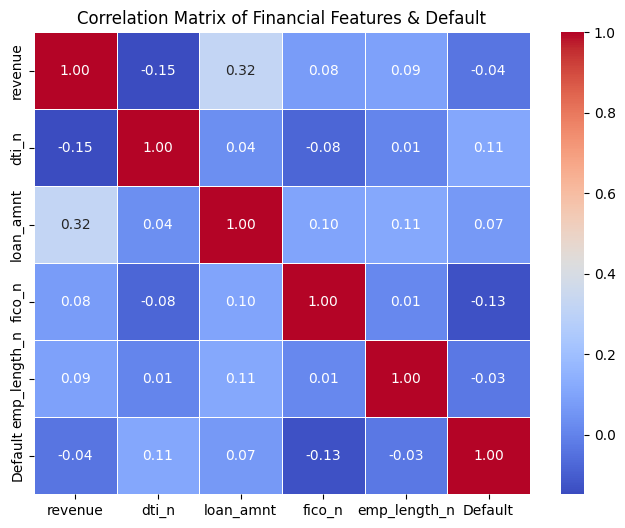

In [7]:
num_cols = ['revenue', 'dti_n', 'loan_amnt', 'fico_n', 'emp_length_n', 'Default']
corr_matrix = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Financial Features & Default')
plt.show()

In [ ]:
# --- FICO Score vs Default Rate ---
# Create FICO score bins (e.g., intervals of 50 points)
df['fico_bin'] = pd.cut(df['fico_n'], bins=range(600, 850, 50))
fico_default = df.groupby('fico_bin', observed=False)['Default'].agg(['count', 'mean']).rename(columns={'count': 'Total_Loans', 'mean': 'Default_Rate'})
print("Default Rate by FICO Score Brackets:")
print(fico_default)
print("-" * 50)

Default Rate by FICO Score Brackets:
            Total_Loans  Default_Rate
fico_bin                             
(600, 650]          231      0.320346
(650, 700]       822001      0.235989
(700, 750]       418367      0.156771
(750, 800]        91109      0.092988
--------------------------------------------------


In [9]:
# Create DTI bins (e.g., intervals of 10)
df['dti_bin'] = pd.cut(df['dti_n'], bins=range(0, 110, 10))
dti_default = df.groupby('dti_bin', observed=False)['Default'].agg(['count', 'mean']).rename(columns={'count': 'Total_Loans', 'mean': 'Default_Rate'})
print("Default Rate by DTI Brackets:")
print(dti_default)
print("-" * 50)

Default Rate by DTI Brackets:
           Total_Loans  Default_Rate
dti_bin                             
(0, 10]         244817      0.148237
(10, 20]        563434      0.178543
(20, 30]        409867      0.230802
(30, 40]        121923      0.291282
(40, 50]          4024      0.320080
(50, 60]          1062      0.284369
(60, 70]           563      0.307282
(70, 80]           320      0.287500
(80, 90]           184      0.315217
(90, 100]          118      0.262712
--------------------------------------------------


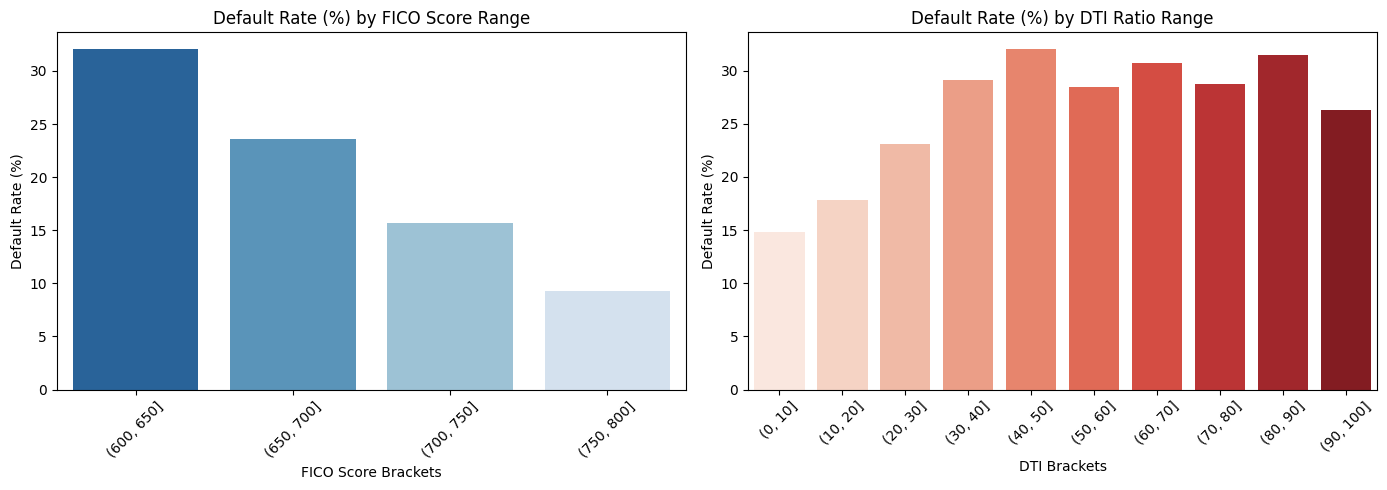

In [15]:
plt.figure(figsize=(14, 5))

# Plot FICO vs Default Rate
plt.subplot(1, 2, 1)
sns.barplot(x=fico_default.index.astype(str), y=fico_default['Default_Rate'] * 100, palette='Blues_r',hue=fico_default.index.astype(str),legend=False)
plt.title('Default Rate (%) by FICO Score Range')
plt.xlabel('FICO Score Brackets')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)

# Plot DTI vs Default Rate
plt.subplot(1, 2, 2)
sns.barplot(x=dti_default.index.astype(str), y=dti_default['Default_Rate'] * 100, palette='Reds', hue=dti_default.index.astype(str), legend=False)
plt.title('Default Rate (%) by DTI Ratio Range')
plt.xlabel('DTI Brackets')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [16]:
# ---  Revenue vs Default Rate (Using Quantiles for skewness) ---
# Create 10 equal-sized revenue buckets (deciles)
df['revenue_decile'] = pd.qcut(df['revenue'], q=10, labels=[f"Decile {i}" for i in range(1, 11)])
revenue_default = df.groupby('revenue_decile', observed=False)['Default'].agg(['count', 'mean']).rename(columns={'count': 'Total_Loans', 'mean': 'Default_Rate'})
print("Default Rate by Revenue Deciles:")
print(revenue_default)
print("-" * 50)

# ---  Loan Amount vs Default Rate ---
# Create loan amount bins (e.g., increments of 5,000)
df['loan_bin'] = pd.cut(df['loan_amnt'], bins=range(0, 45000, 5000))
loan_default = df.groupby('loan_bin', observed=False)['Default'].agg(['count', 'mean']).rename(columns={'count': 'Total_Loans', 'mean': 'Default_Rate'})
print("Default Rate by Loan Amount Brackets:")
print(loan_default)
print("-" * 50)

Default Rate by Revenue Deciles:
                Total_Loans  Default_Rate
revenue_decile                           
Decile 1             154256      0.237663
Decile 2             115197      0.227263
Decile 3             152869      0.218350
Decile 4             122457      0.210605
Decile 5             140762      0.209574
Decile 6             146212      0.197528
Decile 7             116992      0.190329
Decile 8             136478      0.179809
Decile 9             127209      0.166969
Decile 10            134715      0.153420
--------------------------------------------------
Default Rate by Loan Amount Brackets:
                Total_Loans  Default_Rate
loan_bin                                 
(0, 5000]            182890      0.158122
(5000, 10000]        374318      0.172367
(10000, 15000]       284029      0.207799
(15000, 20000]       214210      0.226283
(20000, 25000]       133126      0.228062
(25000, 30000]        77351      0.231813
(30000, 35000]        72033      0.250

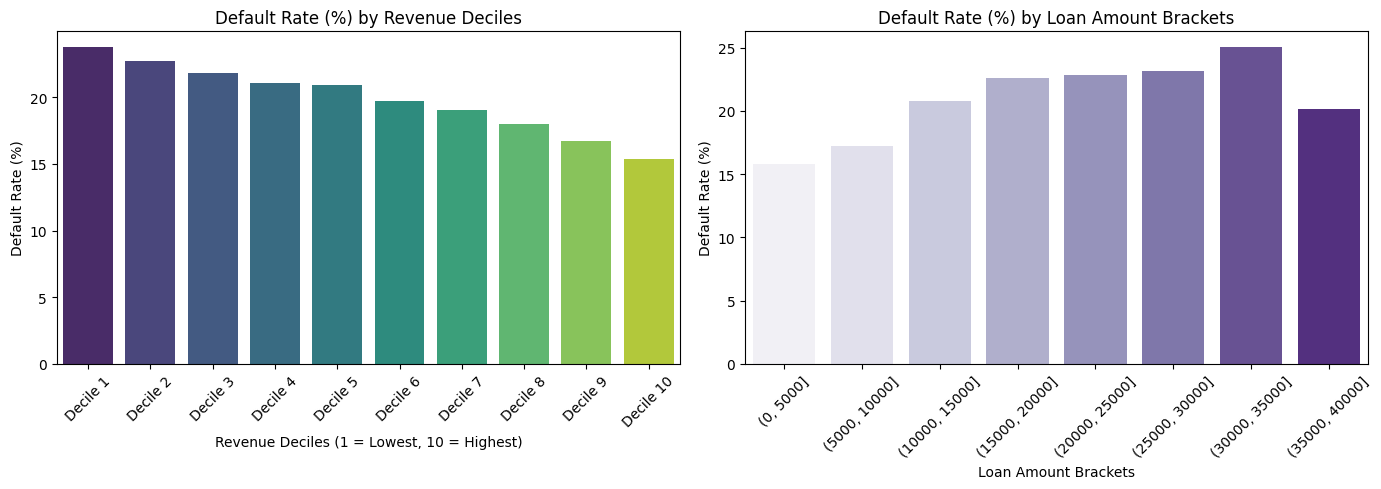

In [18]:
plt.figure(figsize=(14, 5))

# Plot Revenue Deciles vs Default Rate
plt.subplot(1, 2, 1)
sns.barplot(x=revenue_default.index, y=revenue_default['Default_Rate'] * 100, palette='viridis',hue=revenue_default.index, legend=False)
plt.title('Default Rate (%) by Revenue Deciles')
plt.xlabel('Revenue Deciles (1 = Lowest, 10 = Highest)')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)

# Plot Loan Amount Brackets vs Default Rate
plt.subplot(1, 2, 2)
sns.barplot(x=loan_default.index.astype(str), y=loan_default['Default_Rate'] * 100, palette='Purples',hue=loan_default.index.astype(str),legend=False)
plt.title('Default Rate (%) by Loan Amount Brackets')
plt.xlabel('Loan Amount Brackets')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Default Rate by Employment Length (in years, -1 = Unknown):
              Total_Loans  Default_Rate
emp_length_n                           
-1.0                77930      0.269473
 0.0               108409      0.205343
 1.0                88820      0.205877
 2.0               122059      0.198158
 3.0               107839      0.199881
 4.0                80750      0.197573
 5.0                84310      0.196193
 6.0                62869      0.193768
 7.0                59715      0.195093
 8.0                60806      0.199503
 9.0                51015      0.199118
 10.0              442625      0.187972
--------------------------------------------------


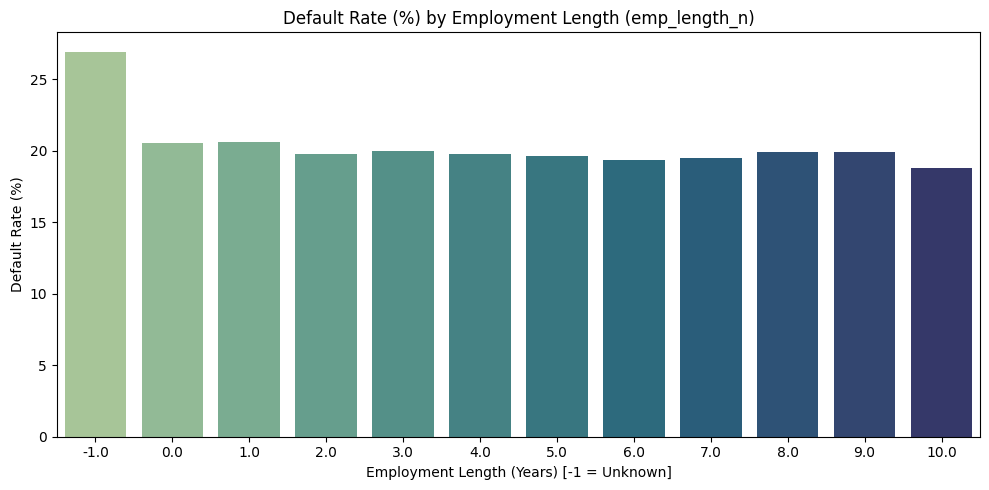

In [20]:
emp_default = df.groupby('emp_length_n')['Default'].agg(['count', 'mean']).rename(columns={'count': 'Total_Loans', 'mean': 'Default_Rate'}).sort_index()

print("Default Rate by Employment Length (in years, -1 = Unknown):")
print(emp_default)
print("-" * 50)

# --- Visualization ---
plt.figure(figsize=(10, 5))

# Plot Employment Length vs Default Rate (%)
sns.barplot(x=emp_default.index, y=emp_default['Default_Rate'] * 100, palette='crest',hue=emp_default.index, legend=False)
plt.title('Default Rate (%) by Employment Length (emp_length_n)')
plt.xlabel('Employment Length (Years) [-1 = Unknown]')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [21]:
# Aggregate loan volume and default rate by state
state_default = df.groupby('addr_state')['Default'].agg(['count', 'mean']).rename(columns={'count': 'Total_Loans', 'mean': 'Default_Rate'}
).sort_values(by='Total_Loans', ascending=False)

print("Top 10 States by Loan Volume & Default Rates:")
print(state_default.head(10))

Top 10 States by Loan Volume & Default Rates:
            Total_Loans  Default_Rate
addr_state                           
CA               196737      0.196252
TX               110251      0.198320
NY               110053      0.220467
FL                95781      0.215011
IL                51842      0.181127
NJ                48568      0.211209
PA                45626      0.208193
OH                43915      0.205124
GA                43458      0.184316
VA                38087      0.199491


In [27]:
# Group by year-month to observe trends over time
df['issue_d'] = pd.to_datetime(df['issue_d'])
df['issue_year_month'] = df['issue_d'].dt.to_period('M')
time_trend = df.groupby('issue_year_month')['Default'].agg(['count', 'mean']).rename(columns={'count': 'Total_Loans', 'mean': 'Default_Rate'})

print("Default Rates Over Time:")
time_trend

Default Rates Over Time:


,Total_Loans,Default_Rate
issue_year_month,,
2007-06,23,0.130435
2007-07,62,0.112903
2007-08,72,0.277778
2007-09,53,0.245283
2007-10,105,0.323810
...,...,...
2018-08,3544,0.088600
2018-09,2415,0.071636
2018-10,2139,0.039738


Yearly Credit & Default Trends:
            Total_Loans  Default_Rate
issue_year                           
2007                599      0.263773
2008               2393      0.207271
2009               5281      0.136906
2010              12537      0.140145
2011              21721      0.151789
2012              53367      0.161973
2013             134804      0.155960
2014             223102      0.184494
2015             375535      0.201851
2016             292979      0.232802
2017             168830      0.231162
2018              55999      0.157342


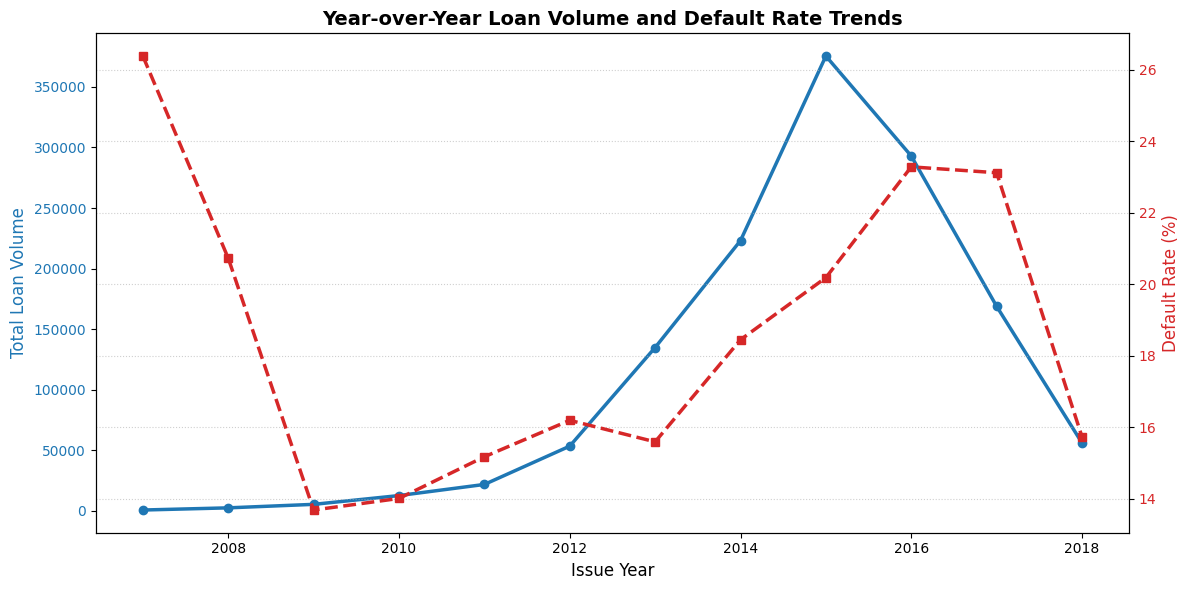

In [28]:
df['issue_year'] = df['issue_d'].dt.year

# Group by year to calculate total loans and average default rate
yearly_trend = df.groupby('issue_year')['Default'].agg(['count', 'mean']).rename(columns={'count': 'Total_Loans', 'mean': 'Default_Rate'})

print("Yearly Credit & Default Trends:")
print(yearly_trend)

# Plotting Year-over-Year Trends
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Total Loan Volume on the primary y-axis (Left)
color = 'tab:blue'
ax1.set_xlabel('Issue Year', fontsize=12)
ax1.set_ylabel('Total Loan Volume', color=color, fontsize=12)
ax1.plot(yearly_trend.index, yearly_trend['Total_Loans'], color=color, marker='o', linewidth=2.5, label='Total Loans')
ax1.tick_params(axis='y', labelcolor=color)

# Create a secondary y-axis (Right) for the Default Rate (%)
ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Default Rate (%)', color=color, fontsize=12)
ax2.plot(yearly_trend.index, yearly_trend['Default_Rate'] * 100, color=color, marker='s', linewidth=2.5, linestyle='--', label='Default Rate (%)')
ax2.tick_params(axis='y', labelcolor=color)

# Title and Layout
plt.title('Year-over-Year Loan Volume and Default Rate Trends', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

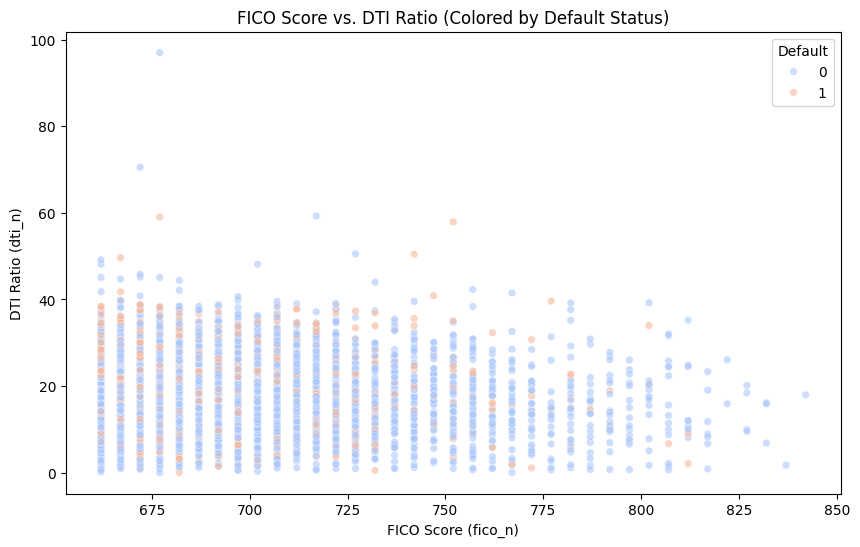

In [23]:
# FICO score and Debt to INcome ratio relationship inspection
df_sample = df.sample(n=5000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_sample, 
    x='fico_n', 
    y='dti_n', 
    hue='Default', 
    palette='coolwarm', 
    alpha=0.6,
    s=30
)
plt.title('FICO Score vs. DTI Ratio (Colored by Default Status)')
plt.xlabel('FICO Score (fico_n)')
plt.ylabel('DTI Ratio (dti_n)')
plt.show()

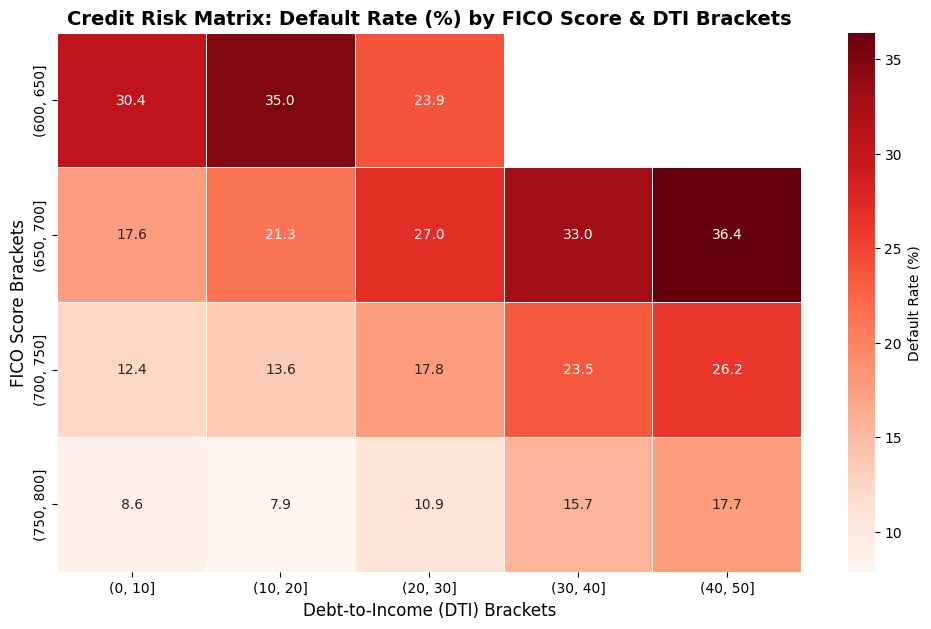

In [29]:
# Create FICO and DTI bins
df['fico_bin'] = pd.cut(df['fico_n'], bins=range(600, 850, 50))
df['dti_bin'] = pd.cut(df['dti_n'], bins=range(0, 60, 10))

# Create a pivot table calculating the average default rate (%) for each intersection
risk_matrix = df.pivot_table(
    index='fico_bin', 
    columns='dti_bin', 
    values='Default', 
    aggfunc='mean',
    observed=False
) * 100

# Plot Heatmap
plt.figure(figsize=(12, 7))
sns.heatmap(risk_matrix, annot=True, fmt='.1f', cmap='Reds', linewidths=0.5, cbar_kws={'label': 'Default Rate (%)'})
plt.title('Credit Risk Matrix: Default Rate (%) by FICO Score & DTI Brackets', fontsize=14, fontweight='bold')
plt.xlabel('Debt-to-Income (DTI) Brackets', fontsize=12)
plt.ylabel('FICO Score Brackets', fontsize=12)
plt.show()

In [30]:
# Group by purpose and home ownership to calculate default rate and loan volume
purpose_home_risk = df.groupby(['purpose', 'home_ownership_n'], observed=False)['Default'].agg(['count', 'mean']).rename(
    columns={'count': 'Total_Loans', 'mean': 'Default_Rate'}
)
purpose_home_risk['Default_Rate'] = purpose_home_risk['Default_Rate'] * 100

print("Default Rate by Loan Purpose & Home Ownership:")
print(purpose_home_risk.sort_values(by='Default_Rate', ascending=False))

Default Rate by Loan Purpose & Home Ownership:
                                     Total_Loans  Default_Rate
purpose            home_ownership_n                           
small_business     RENT                     6958     33.112963
                   OWN                      1673     30.005977
moving             OWN                       583     29.331046
renewable_energy   RENT                      423     29.078014
small_business     MORTGAGE                 6919     26.550079
house              RENT                     3513     25.590663
medical            RENT                     6706     25.231136
moving             OTHER                       4     25.000000
small_business     OTHER                      20     25.000000
other              RENT                    37218     24.404858
debt_consolidation RENT                   318016     24.352548
moving             RENT                     7203     23.934472
medical            OWN                      1917     23.787167
home_imp

In [31]:
# Feature engineering
from sklearn.preprocessing import StandardScaler

print(f"Original dataset shape: {df.shape}")

# --- Handle Skewness (Log Transformation) ---
# Revenue is heavily right-skewed; log1p handles large income ranges smoothly
df['revenue_log'] = np.log1p(df['revenue'])

# --- Categorical Encoding (One-Hot Encoding) ---
# Encode 'purpose' and 'home_ownership_n' into binary columns
categorical_cols = ['purpose', 'home_ownership_n']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

print(f"Dataset shape after One-Hot Encoding: {df_encoded.shape}")

# --- Select Features for Clustering & Modeling ---
# Define numerical features to scale (using log-transformed revenue)
numerical_features = ['revenue_log', 'dti_n', 'loan_amnt', 'fico_n', 'emp_length_n']

# Extract encoded categorical columns dynamically (all columns that start with purpose_ or home_ownership_n_)
encoded_cat_features = [col for col in df_encoded.columns if col.startswith(('purpose_', 'home_ownership_n_'))]

# Combine all modeling features
all_model_features = numerical_features + encoded_cat_features
X_raw = df_encoded[all_model_features]

# --- Feature Scaling (StandardScaler) ---
# Standardize numerical features to mean=0 and variance=1
scaler = StandardScaler()
X_scaled_num = scaler.fit_transform(X_raw[numerical_features])

# Put scaled numerical features back into a DataFrame alongside the binary encoded categorical features
X_scaled_df = pd.DataFrame(X_scaled_num, columns=numerical_features, index=X_raw.index)

for col in encoded_cat_features:
    X_scaled_df[col] = X_raw[col].values

print("Feature scaling complete! Final feature matrix shape:", X_scaled_df.shape)

Original dataset shape: (1347147, 19)
Dataset shape after One-Hot Encoding: (1347147, 34)
Feature scaling complete! Final feature matrix shape: (1347147, 21)


In [32]:
df_encoded.to_csv(r"D:\Sasi\GUVI HCL AI-ML\Credit_Segmentation_Project\dataset\cleaned\featured_loans_granting_model_dataset.csv", index=False)
print('Featured dataset saved successfully')

Featured dataset saved successfully
